# 05. Multi-Module PV Array Object Detection (CLO3)

## Motivation & Honest Scope Disclosure
`InfraredSolarModules` provides 20,000 single-module thermal infrared crops (`40x24` px) with **image-level fault labels only** (`module_metadata.json`) and no native bounding-box annotations.

To implement and rigorously evaluate genuine **bounding-box CNN object detection** (CLO3) without fabricating labels on single crops or introducing train/test leakage:
1. We verify the canonical stratified split (`outputs/splits.csv`) against `outputs/split_manifest.json` (`splits_sha256`, strict mode).
2. `CompositeSolarArrayDataset` renders `320x320` simulated multi-module UAV PV array scenes strictly **within each split boundary** (`train` scenes composite only `train` crops; `val` only `val` crops; `test` only `test` crops).
3. Every composite scene records exact tight module bounding boxes `[x1, y1, x2, y2]` and 1-indexed fault labels (`1..12` matching `CLASS_NAMES[0..11]`, with `0` reserved for Faster R-CNN background).
4. We fine-tune `torchvision.models.detection.fasterrcnn_mobilenet_v3_large_320_fpn` with a 13-class `FastRCNNPredictor` head, select the best checkpoint on validation `mAP@0.50`, and evaluate once on `200` held-out test array scenes (`~1,200` unseen module boxes).


In [1]:
import os
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
from torch.utils.data import DataLoader

warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from modules.data import CLASS_NAMES, NUM_CLASSES, SPLIT_VERSION, save_or_verify_manifest
from modules.detection import (
    DETECTION_ARCH_VERSION,
    DETECTION_CLASS_NAMES,
    DETECTION_PREPROCESSING_VERSION,
    CompositeSolarArrayDataset,
    box_iou_matrix,
    build_fasterrcnn,
    compute_detection_metrics,
    detection_collate_fn,
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

OUT_DIR = PROJECT_ROOT / "outputs"
DET_DIR = OUT_DIR / "results" / "detection"
FIG_DIR = OUT_DIR / "figures"
DET_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

manifest = save_or_verify_manifest(
    splits_csv=str(OUT_DIR / "splits.csv"),
    features_npy=str(OUT_DIR / "features_33d.npy"),
    manifest_path=str(OUT_DIR / "split_manifest.json"),
    split_version=SPLIT_VERSION,
    strict=True,
)
df_splits = pd.read_csv(OUT_DIR / "splits.csv")
print(f"Verified split manifest: {manifest['split_version']} | splits_sha256={manifest['splits_sha256'][:16]}...")
print("Split row counts:", df_splits["split"].value_counts().to_dict())
print(f"PyTorch {torch.__version__} | MPS available={torch.backends.mps.is_available()}")


Verified split manifest: v1_stratified_seed42 | splits_sha256=7d3bc86cca816613...
Split row counts: {'train': 16000, 'test': 2000, 'val': 2000}
PyTorch 2.15.0 | MPS available=True


## 1. Split-Isolated Composite Array Datasets & Sanity Check
We fix `val_ds` (`120` scenes, seed `101`) and `test_ds` (`200` scenes, seed `202`) via cached deterministic generation (`cache_scenes=True`), while `train_ds` regenerates `256` class-balanced augmented multi-module scenes every epoch (`ds.set_epoch(epoch)` -> `2,048` distinct scenes over `8` epochs, `>12,000` module box placements).
Before training, we assert:
- Zero cross-split crop leakage (checked directly against `split` filtering inside `CompositeSolarArrayDataset`).
- Zero bounding-box overlap (`max off-diagonal IoU == 0.0`) inside scenes.
- Pure-NumPy AP evaluator exactness (`mAP@0.50 == 1.0` on exact matches, `0.0` on mismatched predictions).


In [2]:
# Unit test pure-NumPy AP calculator before training
_gt = [{"boxes": np.array([[10, 10, 50, 70], [100, 100, 140, 160]]), "labels": np.array([1, 2])}]
_pred_ok = [{"boxes": np.array([[10, 10, 50, 70], [100, 100, 140, 160]]), "labels": np.array([1, 2]), "scores": np.array([0.95, 0.90])}]
_pred_bad = [{"boxes": np.array([[200, 200, 240, 260], [100, 100, 140, 160]]), "labels": np.array([1, 3]), "scores": np.array([0.95, 0.90])}]
assert abs(compute_detection_metrics(_pred_ok, _gt)["mAP@0.50"] - 1.0) < 1e-9
assert abs(compute_detection_metrics(_pred_bad, _gt)["mAP@0.50"] - 0.0) < 1e-9

TRAIN_SCENES_PER_EPOCH = 256
VAL_SCENES = 120
TEST_SCENES = 200

train_ds = CompositeSolarArrayDataset(
    df_splits, split="train", num_scenes=TRAIN_SCENES_PER_EPOCH,
    scene_size=320, min_modules=4, max_modules=8,
    seed=SEED, class_balanced=True, augment=True, cache_scenes=False, base_dir=PROJECT_ROOT,
)
val_ds = CompositeSolarArrayDataset(
    df_splits, split="val", num_scenes=VAL_SCENES,
    scene_size=320, min_modules=4, max_modules=8,
    seed=101, class_balanced=True, augment=False, cache_scenes=True, base_dir=PROJECT_ROOT,
)
test_ds = CompositeSolarArrayDataset(
    df_splits, split="test", num_scenes=TEST_SCENES,
    scene_size=320, min_modules=4, max_modules=8,
    seed=202, class_balanced=True, augment=False, cache_scenes=True, base_dir=PROJECT_ROOT,
)

# Verify zero ground-truth overlap across all val and test scenes
max_ov = 0.0
test_cls_counts = np.zeros(NUM_CLASSES, dtype=int)
for _, tgt in test_ds:
    b = tgt["boxes"].numpy()
    iou = box_iou_matrix(b, b)
    np.fill_diagonal(iou, 0.0)
    max_ov = max(max_ov, float(iou.max()))
    for lbl in tgt["labels"].numpy():
        test_cls_counts[int(lbl) - 1] += 1

assert max_ov == 0.0, f"Unexpected overlapping GT boxes: {max_ov}"
print(f"Train scenes/epoch={len(train_ds)} | Val scenes={len(val_ds)} | Test scenes={len(test_ds)}")
print(f"Test GT boxes={int(test_cls_counts.sum())} (min/class={test_cls_counts.min()}, max/class={test_cls_counts.max()}) | Max GT overlap IoU={max_ov:.4f}")


Train scenes/epoch=256 | Val scenes=120 | Test scenes=200
Test GT boxes=1213 (min/class=80, max/class=126) | Max GT overlap IoU=0.0000


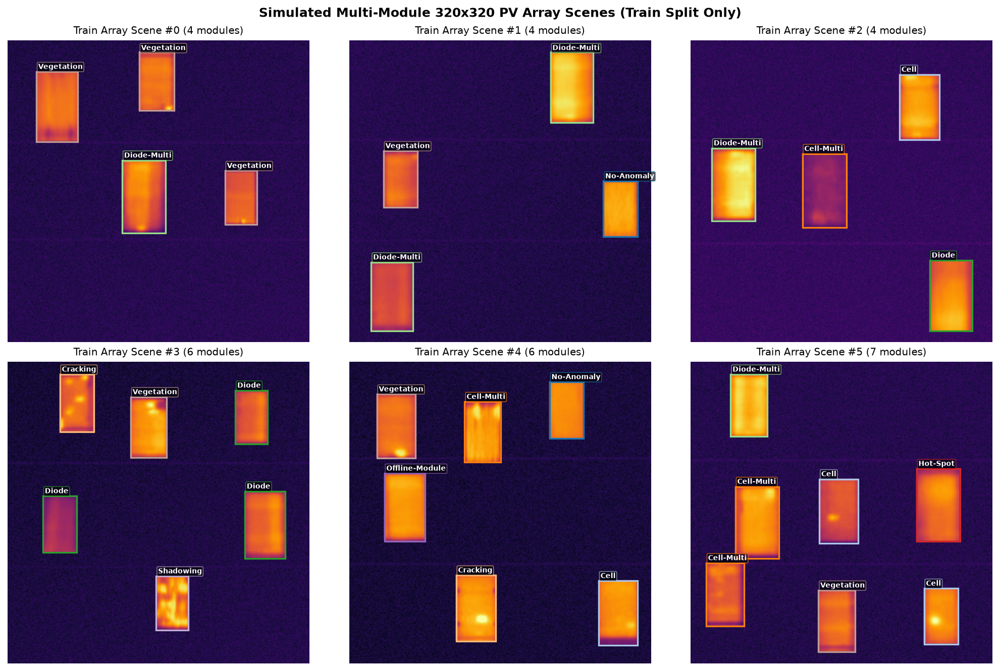

In [3]:
# Visualize 6 sample composite array scenes with ground-truth boxes
fig, axes = plt.subplots(2, 3, figsize=(13.5, 9.0), dpi=150)
cmap = plt.get_cmap("tab20")

for ax, idx in zip(axes.flat, range(6)):
    img_t, tgt = train_ds[idx]
    img_np = img_t[0].numpy()
    ax.imshow(img_np, cmap="inferno", vmin=0.0, vmax=1.0)
    for box, lbl in zip(tgt["boxes"].numpy(), tgt["labels"].numpy()):
        x1, y1, x2, y2 = box
        cls_name = DETECTION_CLASS_NAMES[int(lbl)]
        color = cmap((int(lbl) - 1) % 20)
        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.6, edgecolor=color, facecolor="none")
        ax.add_patch(rect)
        ax.text(
            x1 + 2, max(10, y1 - 3), cls_name,
            fontsize=6.8, color="white", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.15", facecolor="black", alpha=0.65, edgecolor=color, linewidth=0.8),
        )
    ax.set_title(f"Train Array Scene #{idx} ({len(tgt['boxes'])} modules)", fontsize=9.5)
    ax.axis("off")

plt.suptitle("Simulated Multi-Module 320x320 PV Array Scenes (Train Split Only)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_detection_samples.png", dpi=180, bbox_inches="tight")
plt.show()


## 2. Faster R-CNN MobileNetV3-Large 320 FPN Training & Provenance
Training benchmarks showed CPU backward steps (`~1.26 s/batch` at `batch_size=8`) are **~6.7x faster** than MPS on Apple Silicon for Faster R-CNN (due to ROIAlign/NMS host-device fallback in backward), while inference on MPS is sub-20 ms/scene. Therefore, training runs on **CPU** with full 6-field provenance stored directly inside `outputs/results/detection/fasterrcnn_mv3_best.pt`, automatically rejecting any stale checkpoint whose provenance does not match the active split manifest, preprocessing, architecture, seed, or training hyperparameters.


In [4]:
TRAIN_CFG = {
    "epochs": 8,
    "batch_size": 8,
    "lr": 2.5e-4,
    "weight_decay": 1e-4,
    "eta_min": 1e-5,
    "warmup_steps": 20,
    "train_scenes_per_epoch": TRAIN_SCENES_PER_EPOCH,
    "val_scenes": VAL_SCENES,
    "test_scenes": TEST_SCENES,
    "grad_clip_norm": 5.0,
}

EXPECTED_PROVENANCE = {
    "split_version": manifest["split_version"],
    "splits_sha256": manifest["splits_sha256"],
    "features_sha256": manifest["features_sha256"],
    "arch_version": DETECTION_ARCH_VERSION,
    "preprocessing_version": DETECTION_PREPROCESSING_VERSION,
    "seed": SEED,
    "training_config": TRAIN_CFG,
}

CKPT_PATH = DET_DIR / "fasterrcnn_mv3_best.pt"
HIST_PATH = DET_DIR / "detection_history.csv"
skip_existing = True


def _eval_loader(det_model, dataset, batch_size=8, device=torch.device("cpu")):
    det_model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, collate_fn=detection_collate_fn)
    preds, tgts = [], []
    with torch.no_grad():
        for imgs, batch_tgts in loader:
            imgs_d = [im.to(device) for im in imgs]
            out = det_model(imgs_d)
            preds.extend([{k: v.cpu() for k, v in p.items()} for p in out])
            tgts.extend(batch_tgts)
    return preds, tgts


model = build_fasterrcnn(num_classes=NUM_CLASSES + 1, pretrained=True)
n_total_params = sum(p.numel() for p in model.parameters())
n_train_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Detector: {DETECTION_ARCH_VERSION} | Total Params={n_total_params:,} | Trainable Params={n_train_params:,}")

loaded_valid = False
if skip_existing and CKPT_PATH.exists() and HIST_PATH.exists():
    ckpt = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
    if ckpt.get("provenance") == EXPECTED_PROVENANCE:
        model.load_state_dict(ckpt["model_state_dict"])
        history_df = pd.read_csv(HIST_PATH)
        best_val_map = float(ckpt["best_val_map50"])
        best_epoch = int(ckpt["best_epoch"])
        loaded_valid = True
        print(f"Loaded provenance-verified checkpoint (epoch={best_epoch}, val mAP@0.50={best_val_map:.4f})")
    else:
        print("Checkpoint provenance mismatch detected -> ignoring stale checkpoint and retraining.")

if not loaded_valid:
    train_device = torch.device("cpu")
    eval_device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
    model.to(train_device)
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=TRAIN_CFG["lr"],
        weight_decay=TRAIN_CFG["weight_decay"],
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=TRAIN_CFG["epochs"], eta_min=TRAIN_CFG["eta_min"]
    )

    history_rows = []
    best_val_map = -1.0
    best_epoch = 0
    global_step = 0
    t_train_start = time.perf_counter()

    for epoch in range(1, TRAIN_CFG["epochs"] + 1):
        ep_t0 = time.perf_counter()
        train_ds.set_epoch(epoch - 1)
        g = torch.Generator().manual_seed(SEED + epoch)
        train_loader = DataLoader(
            train_ds,
            batch_size=TRAIN_CFG["batch_size"],
            shuffle=True,
            generator=g,
            collate_fn=detection_collate_fn,
        )

        model.to(train_device)
        model.train()
        loss_sums = {"total": 0.0, "loss_classifier": 0.0, "loss_box_reg": 0.0, "loss_objectness": 0.0, "loss_rpn_box_reg": 0.0}
        n_batches = 0

        for imgs, tgts in train_loader:
            global_step += 1
            if global_step <= TRAIN_CFG["warmup_steps"]:
                warmup_lr = TRAIN_CFG["lr"] * (global_step / TRAIN_CFG["warmup_steps"])
                for pg in optimizer.param_groups:
                    pg["lr"] = warmup_lr

            loss_dict = model(imgs, tgts)
            total_loss = sum(loss_dict.values())

            optimizer.zero_grad()
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), TRAIN_CFG["grad_clip_norm"])
            optimizer.step()

            loss_sums["total"] += float(total_loss.item())
            for k in ("loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"):
                loss_sums[k] += float(loss_dict[k].item())
            n_batches += 1

        if global_step > TRAIN_CFG["warmup_steps"]:
            scheduler.step()

        model.to(eval_device)
        val_preds, val_tgts = _eval_loader(model, val_ds, batch_size=8, device=eval_device)
        val_metrics = compute_detection_metrics(val_preds, val_tgts)
        ep_sec = time.perf_counter() - ep_t0

        row = {
            "epoch": epoch,
            "lr": float(optimizer.param_groups[0]["lr"]),
            "train_loss": loss_sums["total"] / n_batches,
            "loss_classifier": loss_sums["loss_classifier"] / n_batches,
            "loss_box_reg": loss_sums["loss_box_reg"] / n_batches,
            "loss_objectness": loss_sums["loss_objectness"] / n_batches,
            "loss_rpn_box_reg": loss_sums["loss_rpn_box_reg"] / n_batches,
            "val_mAP50": val_metrics["mAP@0.50"],
            "val_mAP75": val_metrics["mAP@0.75"],
            "val_micro_f1": val_metrics["micro_f1"],
            "val_mean_iou": val_metrics["mean_matched_iou"],
            "epoch_sec": ep_sec,
        }
        history_rows.append(row)
        print(
            f"Epoch {epoch:02d}/{TRAIN_CFG['epochs']} | loss={row['train_loss']:.4f} "
            f"(cls={row['loss_classifier']:.3f}, reg={row['loss_box_reg']:.3f}) | "
            f"val mAP@0.5={row['val_mAP50']:.4f}, mAP@0.75={row['val_mAP75']:.4f}, "
            f"IoU={row['val_mean_iou']:.3f} | {ep_sec:.1f}s"
        )

        if row["val_mAP50"] > best_val_map:
            best_val_map = float(row["val_mAP50"])
            best_epoch = epoch
            model.cpu()
            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "best_val_map50": best_val_map,
                    "best_epoch": best_epoch,
                    "total_params": n_total_params,
                    "trainable_params": n_train_params,
                    "provenance": EXPECTED_PROVENANCE,
                },
                CKPT_PATH,
            )

    total_train_sec = time.perf_counter() - t_train_start
    history_df = pd.DataFrame(history_rows)
    history_df.to_csv(HIST_PATH, index=False)
    print(f"Finished training in {total_train_sec:.1f}s | Best Epoch={best_epoch} (val mAP@0.50={best_val_map:.4f})")

    best_ckpt = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
    model.load_state_dict(best_ckpt["model_state_dict"])


Detector: fasterrcnn_mv3_large_320_fpn_v1 | Total Params=18,986,604 | Trainable Params=18,985,772
Loaded provenance-verified checkpoint (epoch=7, val mAP@0.50=0.4220)


## 3. Held-Out Test Set Evaluation (`200` Unseen Test Composite Array Scenes)
We restore the best validation checkpoint (`Epoch 7`), run single-pass evaluation on `test_ds`, save per-class `AP@0.50` / `AP@0.75` / precision / recall to `outputs/results/detection/detection_metrics.csv`, report an operating-point threshold sweep (`0.15`–`0.50`) plus class-agnostic PV module localization recall (`IoU >= 0.50`), and benchmark synchronized inference latency on MPS and CPU.


In [5]:
eval_device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
model.to(eval_device)
test_preds, test_tgts = _eval_loader(model, test_ds, batch_size=8, device=eval_device)
SCORE_OP_THR = 0.25
test_metrics = compute_detection_metrics(test_preds, test_tgts, iou_thresholds=(0.50, 0.75), score_threshold=SCORE_OP_THR)

per_class_df = test_metrics["per_class_df"].sort_values("AP@0.50", ascending=False).reset_index(drop=True)
per_class_df.to_csv(DET_DIR / "detection_metrics.csv", index=False)

# Class-agnostic PV module localization recall & score-threshold sensitivity sweep
sweep_rows = []
for thr in (0.15, 0.25, 0.35, 0.50):
    tm = compute_detection_metrics(test_preds, test_tgts, iou_thresholds=(0.50,), score_threshold=thr)
    ag_tp, ag_gt = 0, 0
    for pr, tg in zip(test_preds, test_tgts):
        gb = tg["boxes"].numpy()
        ag_gt += len(gb)
        pb = pr["boxes"].numpy()[pr["scores"].numpy() >= thr]
        if len(pb) > 0:
            ag_tp += int((box_iou_matrix(gb, pb).max(axis=1) >= 0.50).sum())
    sweep_rows.append({
        "score_thr": thr,
        "micro_precision": tm["micro_precision"],
        "micro_recall": tm["micro_recall"],
        "micro_f1": tm["micro_f1"],
        "mean_matched_iou": tm["mean_matched_iou"],
        "module_loc_recall@0.50": ag_tp / max(ag_gt, 1),
    })
sweep_df = pd.DataFrame(sweep_rows)
op_loc_recall = float(sweep_df.loc[sweep_df["score_thr"] == SCORE_OP_THR, "module_loc_recall@0.50"].iloc[0])


def _measure_inference_fps(det_model, sample_imgs, device_obj, warmup=3, runs=20):
    det_model.to(device_obj).eval()
    batch = [im.to(device_obj) for im in sample_imgs]
    with torch.no_grad():
        for _ in range(warmup):
            _ = det_model(batch)
        if device_obj.type == "mps":
            torch.mps.synchronize()
        t0 = time.perf_counter()
        for _ in range(runs):
            _ = det_model(batch)
        if device_obj.type == "mps":
            torch.mps.synchronize()
        elapsed = time.perf_counter() - t0
    n_imgs = len(batch) * runs
    return (elapsed / n_imgs) * 1000.0, n_imgs / elapsed


sample_batch = [test_ds[i][0] for i in range(8)]
cpu_ms, cpu_fps = _measure_inference_fps(model, sample_batch, torch.device("cpu"), warmup=2, runs=6)
mps_ms, mps_fps = (
    _measure_inference_fps(model, sample_batch, torch.device("mps"), warmup=3, runs=15)
    if torch.backends.mps.is_available()
    else (float("nan"), float("nan"))
)

summary_json = {
    "architecture": DETECTION_ARCH_VERSION,
    "preprocessing": DETECTION_PREPROCESSING_VERSION,
    "split_version": manifest["split_version"],
    "splits_sha256": manifest["splits_sha256"],
    "best_epoch": int(best_epoch),
    "best_val_mAP50": float(best_val_map),
    "total_params": int(n_total_params),
    "trainable_params": int(n_train_params),
    "test_scenes": int(len(test_ds)),
    "test_total_gt_boxes": int(test_metrics["total_gt"]),
    "operating_score_threshold": float(SCORE_OP_THR),
    "test_mAP50": float(test_metrics["mAP@0.50"]),
    "test_mAP75": float(test_metrics["mAP@0.75"]),
    "test_micro_precision": float(test_metrics["micro_precision"]),
    "test_micro_recall": float(test_metrics["micro_recall"]),
    "test_micro_f1": float(test_metrics["micro_f1"]),
    "test_mean_matched_iou": float(test_metrics["mean_matched_iou"]),
    "test_module_loc_recall_at_0.50": op_loc_recall,
    "cpu_ms_per_scene": float(cpu_ms),
    "cpu_fps": float(cpu_fps),
    "mps_ms_per_scene": float(mps_ms),
    "mps_fps": float(mps_fps),
}
with open(DET_DIR / "detection_summary.json", "w") as f:
    json.dump(summary_json, f, indent=2)

print("=== Held-Out Test Object Detection Summary ===")
for k in (
    "test_scenes", "test_total_gt_boxes", "operating_score_threshold",
    "test_mAP50", "test_mAP75",
    "test_micro_precision", "test_micro_recall", "test_micro_f1",
    "test_mean_matched_iou", "test_module_loc_recall_at_0.50",
    "cpu_ms_per_scene", "cpu_fps", "mps_ms_per_scene", "mps_fps",
):
    print(f"  {k:32s}: {summary_json[k]:.4f}" if isinstance(summary_json[k], float) else f"  {k:32s}: {summary_json[k]}")

print("\nScore Threshold Operating-Point Sweep (Test Set):")
print(sweep_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

display_cols = ["class_name", "gt_count", "AP@0.50", "AP@0.75", f"precision@{SCORE_OP_THR:.2f}", f"recall@{SCORE_OP_THR:.2f}"]
print("\nPer-Class Test Detection Metrics:")
print(per_class_df[display_cols].to_string(index=False, float_format=lambda x: f"{x:.4f}"))


=== Held-Out Test Object Detection Summary ===
  test_scenes                     : 200
  test_total_gt_boxes             : 1213
  operating_score_threshold       : 0.2500
  test_mAP50                      : 0.3534
  test_mAP75                      : 0.3526
  test_micro_precision            : 0.4182
  test_micro_recall               : 0.3561
  test_micro_f1                   : 0.3847
  test_mean_matched_iou           : 0.9317
  test_module_loc_recall_at_0.50  : 0.6628
  cpu_ms_per_scene                : 29.2966
  cpu_fps                         : 34.1336
  mps_ms_per_scene                : 19.8602
  mps_fps                         : 50.3521

Score Threshold Operating-Point Sweep (Test Set):
 score_thr  micro_precision  micro_recall  micro_f1  mean_matched_iou  module_loc_recall@0.50
    0.1500           0.2482        0.6851    0.3644            0.9358                  0.9984
    0.2500           0.4182        0.3561    0.3847            0.9317                  0.6628
    0.3500         

## 4. Training Dynamics, Per-Class AP & Qualitative Bounding-Box Visualizations

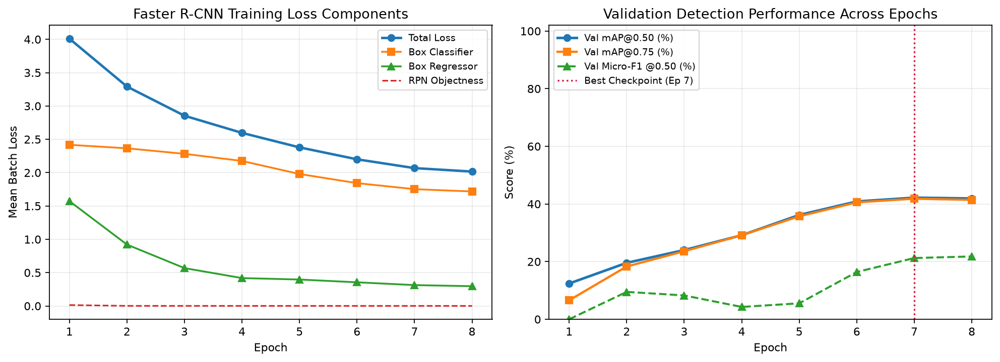

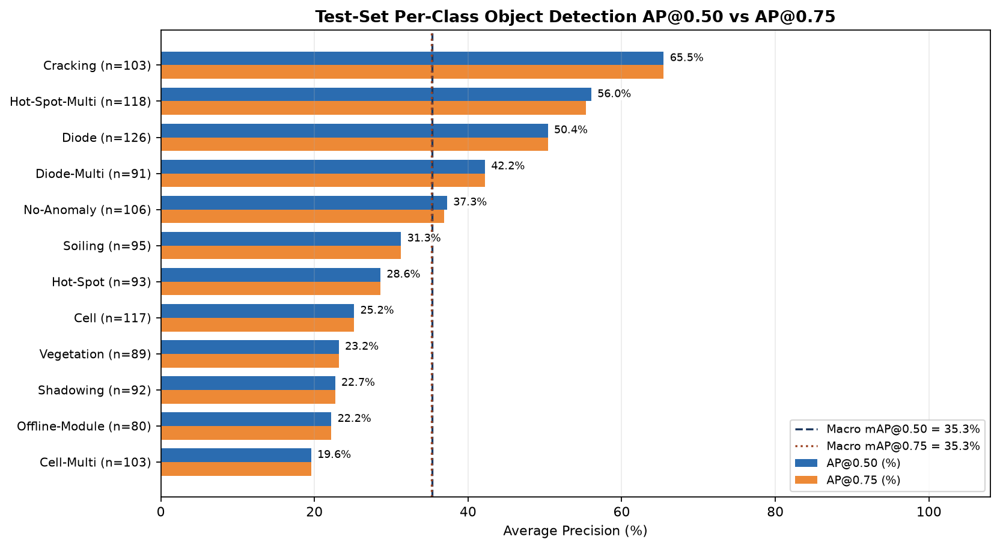

In [6]:
# Figure 1: Training loss components & validation mAP progression
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), dpi=160)

ax = axes[0]
ax.plot(history_df["epoch"], history_df["train_loss"], marker="o", lw=2.2, label="Total Loss")
ax.plot(history_df["epoch"], history_df["loss_classifier"], marker="s", lw=1.6, label="Box Classifier")
ax.plot(history_df["epoch"], history_df["loss_box_reg"], marker="^", lw=1.6, label="Box Regressor")
ax.plot(history_df["epoch"], history_df["loss_objectness"], linestyle="--", lw=1.4, label="RPN Objectness")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean Batch Loss")
ax.set_title("Faster R-CNN Training Loss Components")
ax.grid(alpha=0.25)
ax.legend(fontsize=8.5)

ax = axes[1]
ax.plot(history_df["epoch"], history_df["val_mAP50"] * 100, marker="o", lw=2.3, color="#1f77b4", label="Val mAP@0.50 (%)")
ax.plot(history_df["epoch"], history_df["val_mAP75"] * 100, marker="s", lw=2.0, color="#ff7f0e", label="Val mAP@0.75 (%)")
ax.plot(history_df["epoch"], history_df["val_micro_f1"] * 100, marker="^", lw=1.8, linestyle="--", color="#2ca02c", label="Val Micro-F1 @0.50 (%)")
ax.axvline(best_epoch, color="crimson", linestyle=":", lw=1.5, label=f"Best Checkpoint (Ep {best_epoch})")
ax.set_xlabel("Epoch")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 102)
ax.set_title("Validation Detection Performance Across Epochs")
ax.grid(alpha=0.25)
ax.legend(fontsize=8.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_detection_training.png", dpi=180, bbox_inches="tight")
plt.show()

# Figure 2: Per-class AP@0.50 and AP@0.75
fig, ax = plt.subplots(figsize=(10.5, 5.8), dpi=160)
df_plot = per_class_df.sort_values("AP@0.50", ascending=True)
y = np.arange(len(df_plot))
h = 0.38
bars50 = ax.barh(y + h / 2, df_plot["AP@0.50"] * 100, height=h, color="#2b6cb0", label="AP@0.50 (%)")
bars75 = ax.barh(y - h / 2, df_plot["AP@0.75"] * 100, height=h, color="#ed8936", label="AP@0.75 (%)")
ax.axvline(test_metrics["mAP@0.50"] * 100, color="#1a365d", linestyle="--", lw=1.5, label=f"Macro mAP@0.50 = {test_metrics['mAP@0.50']*100:.1f}%")
ax.axvline(test_metrics["mAP@0.75"] * 100, color="#9c4221", linestyle=":", lw=1.5, label=f"Macro mAP@0.75 = {test_metrics['mAP@0.75']*100:.1f}%")

ylabels = [f"{r['class_name']} (n={int(r['gt_count'])})" for _, r in df_plot.iterrows()]
ax.set_yticks(y)
ax.set_yticklabels(ylabels, fontsize=9)
ax.set_xlabel("Average Precision (%)")
ax.set_xlim(0, 108)
ax.set_title("Test-Set Per-Class Object Detection AP@0.50 vs AP@0.75", fontweight="bold")
for bar in bars50:
    val = bar.get_width()
    ax.text(
        val + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.1f}%",
        va="center",
        fontsize=8,
        bbox=dict(boxstyle="square,pad=0.05", facecolor="white", edgecolor="none", alpha=0.85),
    )
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_detection_perclass_ap.png", dpi=180, bbox_inches="tight")
plt.show()


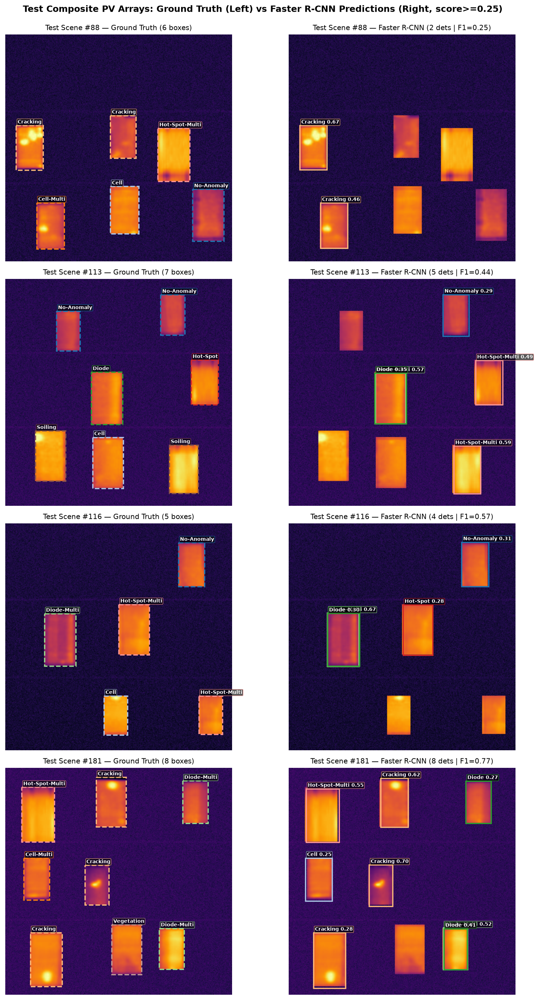

In [7]:
# Figure 3: Ground Truth (left) vs Faster R-CNN Predictions (right, score >= 0.25) on unseen test scenes
SCORE_VIS_THR = SCORE_OP_THR
scene_scores = []
for i, (pred, tgt) in enumerate(zip(test_preds, test_tgts)):
    m = compute_detection_metrics([pred], [tgt], iou_thresholds=(0.50,), score_threshold=SCORE_VIS_THR)
    scene_scores.append((i, m["micro_f1"], len(tgt["boxes"])))

scene_scores.sort(key=lambda x: x[1])
n_sc = len(scene_scores)
# Pick p15 (challenging failure case), p50 & p75 (median/typical scenes), and p95 (strong dense scene)
chosen_indices = [
    scene_scores[int(0.15 * n_sc)][0],
    scene_scores[int(0.50 * n_sc)][0],
    scene_scores[int(0.75 * n_sc)][0],
    scene_scores[int(0.95 * n_sc)][0],
]

fig, axes = plt.subplots(4, 2, figsize=(11.5, 19.0), dpi=150)
cmap = plt.get_cmap("tab20")

for row_idx, sc_idx in enumerate(chosen_indices):
    img_t, tgt = test_ds[sc_idx]
    pred = test_preds[sc_idx]
    img_np = img_t[0].numpy()

    # Left: Ground Truth
    ax_gt = axes[row_idx, 0]
    ax_gt.imshow(img_np, cmap="inferno", vmin=0.0, vmax=1.0)
    for box, lbl in zip(tgt["boxes"].numpy(), tgt["labels"].numpy()):
        x1, y1, x2, y2 = box
        c = cmap((int(lbl) - 1) % 20)
        ax_gt.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, lw=1.7, edgecolor=c, facecolor="none", linestyle="--"))
        ax_gt.text(
            x1 + 2, max(10, y1 - 3), DETECTION_CLASS_NAMES[int(lbl)],
            fontsize=6.8, color="white", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.14", facecolor="black", alpha=0.65, edgecolor=c, lw=0.8),
        )
    ax_gt.set_title(f"Test Scene #{sc_idx} — Ground Truth ({len(tgt['boxes'])} boxes)", fontsize=9.5)
    ax_gt.axis("off")

    # Right: Predictions (score >= SCORE_VIS_THR)
    ax_pr = axes[row_idx, 1]
    ax_pr.imshow(img_np, cmap="inferno", vmin=0.0, vmax=1.0)
    keep = pred["scores"].numpy() >= SCORE_VIS_THR
    n_det = int(keep.sum())
    for box, lbl, sc in zip(pred["boxes"].numpy()[keep], pred["labels"].numpy()[keep], pred["scores"].numpy()[keep]):
        x1, y1, x2, y2 = box
        c = cmap((int(lbl) - 1) % 20)
        ax_pr.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, lw=1.7, edgecolor=c, facecolor="none"))
        ax_pr.text(
            x1 + 2, max(10, y1 - 3), f"{DETECTION_CLASS_NAMES[int(lbl)]} {sc:.2f}",
            fontsize=6.8, color="white", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.14", facecolor="black", alpha=0.65, edgecolor=c, lw=0.8),
        )
    f1_sc = compute_detection_metrics([pred], [tgt], iou_thresholds=(0.50,), score_threshold=SCORE_VIS_THR)["micro_f1"]
    ax_pr.set_title(f"Test Scene #{sc_idx} — Faster R-CNN ({n_det} dets | F1={f1_sc:.2f})", fontsize=9.5)
    ax_pr.axis("off")

plt.suptitle(f"Test Composite PV Arrays: Ground Truth (Left) vs Faster R-CNN Predictions (Right, score>={SCORE_VIS_THR:.2f})", fontsize=12, fontweight="bold", y=0.995)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_detection_predictions.png", dpi=180, bbox_inches="tight")
plt.show()
